In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils import resample
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
df = pd.read_csv('/content/IMDB Dataset.csv')  # upload from Kaggle
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
# 3. Text Cleaning and Heuristic Labeling
spoiler_keywords = [
    'dies', 'killed', 'real identity', 'turns out', 'betrays',
    'in the end', 'he was', 'she was', 'was actually',
    'revealed that', 'they reveal', 'the killer is', 'secretly', 'the murderer'
]

def is_spoiler(text):
    return int(any(kw in text.lower() for kw in spoiler_keywords))

def clean_text(text):
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z ]', '', text)
    return text.lower()

df['review'] = df['review'].apply(clean_text)
df['spoiler'] = df['review'].apply(is_spoiler)


In [5]:
# 4. Balance the Dataset
df_majority = df[df.spoiler == 0]
df_minority = df[df.spoiler == 1]

df_majority_downsampled = resample(df_majority,
                                   replace=False,
                                   n_samples=len(df_minority),
                                   random_state=42)

df_balanced = pd.concat([df_majority_downsampled, df_minority])
df_balanced = df_balanced.sample(frac=1).reset_index(drop=True)


In [6]:
# 5. TF-IDF + XGBoost
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 3), stop_words='english')
X = vectorizer.fit_transform(df_balanced['review'])
y = df_balanced['spoiler']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

model_xgb = XGBClassifier()
model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)

In [7]:
print("\nXGBoost Classification Report")
print(classification_report(y_test, y_pred_xgb))


XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.74      0.84      0.79      2249
           1       0.82      0.71      0.76      2248

    accuracy                           0.78      4497
   macro avg       0.78      0.78      0.78      4497
weighted avg       0.78      0.78      0.78      4497



In [8]:
# 6. BiLSTM + GloVe
# Tokenization
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df_balanced['review'])
sequences = tokenizer.texts_to_sequences(df_balanced['review'])

max_len = 200
X_seq = pad_sequences(sequences, maxlen=max_len)
y = df_balanced['spoiler']

X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(X_seq, y, test_size=0.2, stratify=y)


In [9]:
# Load GloVe
glove_path = '/content/glove.6B.100d.txt'
embedding_index = {}
with open(glove_path) as f:
    for line in f:
        values = line.split()
        word = values[0]
        coeffs = np.asarray(values[1:], dtype='float32')
        embedding_index[word] = coeffs

embedding_matrix = np.zeros((10000, 100))
for word, i in tokenizer.word_index.items():
    if i < 10000:
        vec = embedding_index.get(word)
        if vec is not None:
            embedding_matrix[i] = vec

In [10]:
# LSTM Model
model_lstm = Sequential([
    Embedding(input_dim=10000, output_dim=100, weights=[embedding_matrix],
              input_length=max_len, trainable=False),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model_lstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model_lstm.summary()

history = model_lstm.fit(X_train_seq, y_train_seq, epochs=5, batch_size=128, validation_split=0.1)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │       1,000,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

Epoch 1/5
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.6301 - loss: 0.6574 - val_accuracy: 0.6554 - val_loss: 0.6280
Epoch 2/5
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6576 - loss: 0.6345 - val_accuracy: 0.6593 - val_loss: 0.6281
Epoch 3/5
127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6570 - loss: 0.6294 - val_accuracy: 0.6604 - val_loss: 0.6242
Epoch 4/5
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6680 - loss: 0.6208 - val_accuracy: 0.6709 - val_loss: 0.6144
Epoch 5/5
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6831 - loss: 0.6010 - val_accuracy: 0.6804 - val_loss: 0.6024


141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step

BiLSTM Classification Report
              precision    recall  f1-score   support

           0       0.76      0.55      0.64      2249
           1       0.65      0.83      0.73      2248

    accuracy                           0.69      4497
   macro avg       0.71      0.69      0.68      4497
weighted avg       0.71      0.69      0.68      4497

Precision: 0.6495098039215687
Recall: 0.8251779359430605
F1 Score: 0.7268808777429467


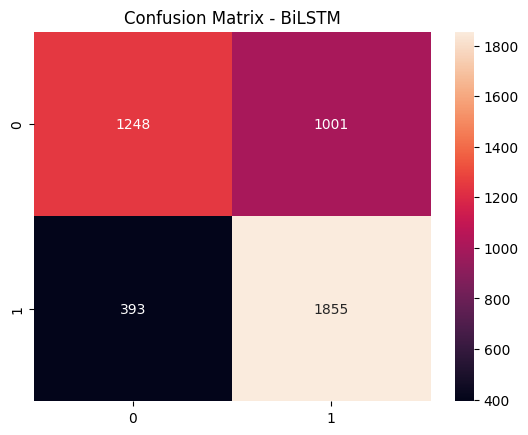

In [11]:
# Evaluate LSTM
probs = model_lstm.predict(X_test_seq)
y_pred_lstm = (probs > 0.4).astype('int32')  # Custom threshold

print("\nBiLSTM Classification Report")
print(classification_report(y_test_seq, y_pred_lstm))

print("Precision:", precision_score(y_test_seq, y_pred_lstm))
print("Recall:", recall_score(y_test_seq, y_pred_lstm))
print("F1 Score:", f1_score(y_test_seq, y_pred_lstm))

sns.heatmap(confusion_matrix(y_test_seq, y_pred_lstm), annot=True, fmt='d')
plt.title("Confusion Matrix - BiLSTM")
plt.show()

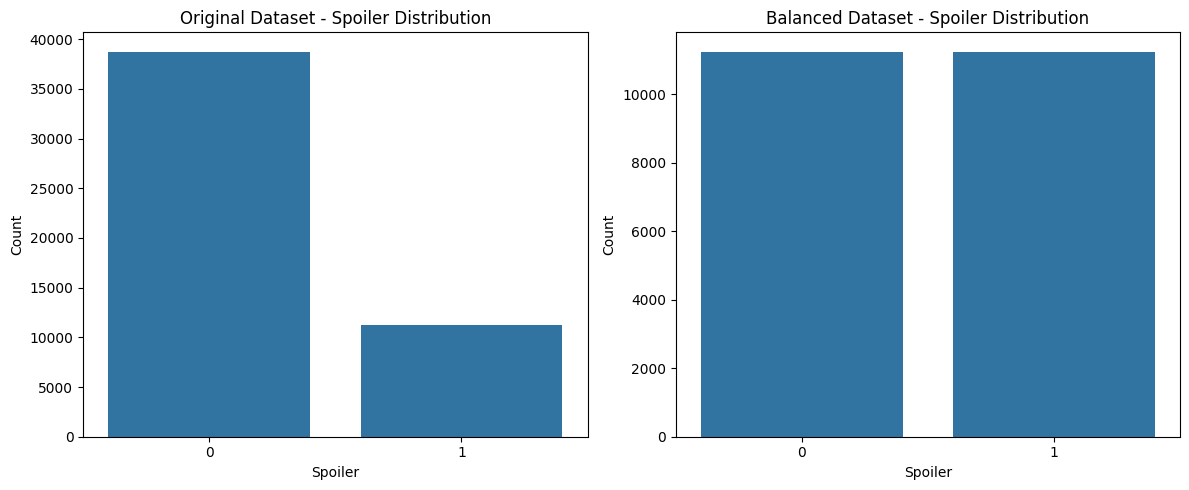

In [14]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='spoiler')
plt.title("Original Dataset - Spoiler Distribution")
plt.xlabel("Spoiler")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
sns.countplot(data=df_balanced, x='spoiler')
plt.title("Balanced Dataset - Spoiler Distribution")
plt.xlabel("Spoiler")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


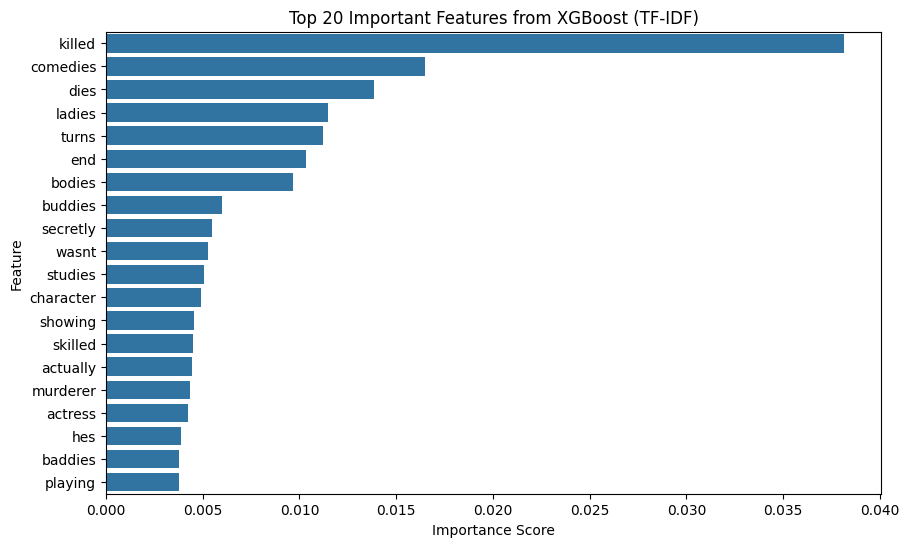

In [15]:
importances = model_xgb.feature_importances_
indices = np.argsort(importances)[-20:][::-1]
features = np.array(vectorizer.get_feature_names_out())[indices]

plt.figure(figsize=(10,6))
sns.barplot(x=importances[indices], y=features)
plt.title("Top 20 Important Features from XGBoost (TF-IDF)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


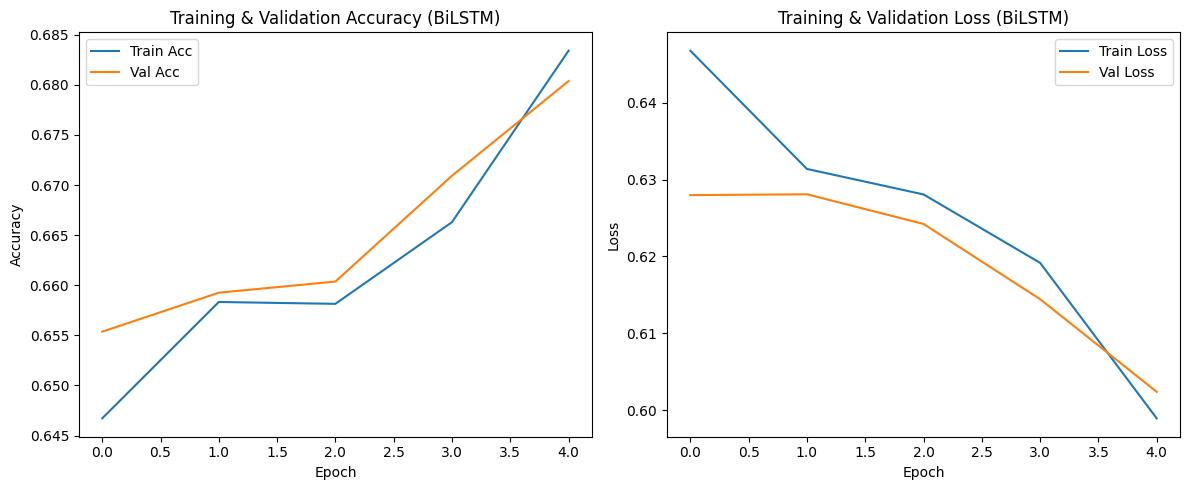

In [16]:
# Accuracy
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Training & Validation Accuracy (BiLSTM)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Training & Validation Loss (BiLSTM)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


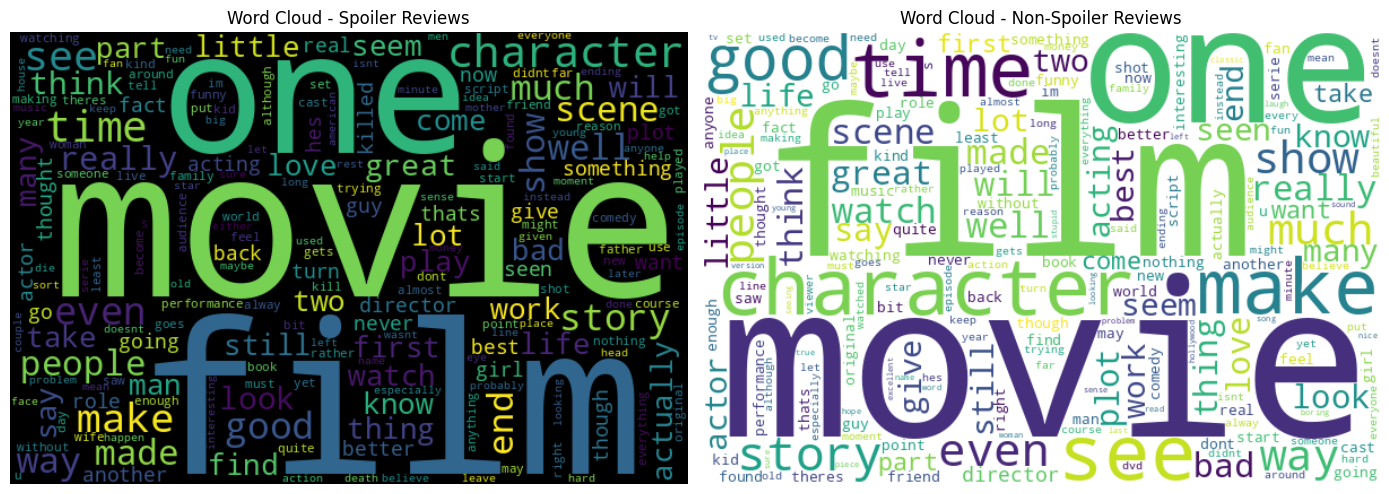

In [17]:
from wordcloud import WordCloud

spoiler_text = ' '.join(df_balanced[df_balanced['spoiler']==1]['review'])
non_spoiler_text = ' '.join(df_balanced[df_balanced['spoiler']==0]['review'])

plt.figure(figsize=(14,6))

plt.subplot(1, 2, 1)
wordcloud_spoiler = WordCloud(width=600, height=400, background_color='black').generate(spoiler_text)
plt.imshow(wordcloud_spoiler, interpolation='bilinear')
plt.title("Word Cloud - Spoiler Reviews")
plt.axis('off')

plt.subplot(1, 2, 2)
wordcloud_non = WordCloud(width=600, height=400, background_color='white').generate(non_spoiler_text)
plt.imshow(wordcloud_non, interpolation='bilinear')
plt.title("Word Cloud - Non-Spoiler Reviews")
plt.axis('off')

plt.tight_layout()
plt.show()


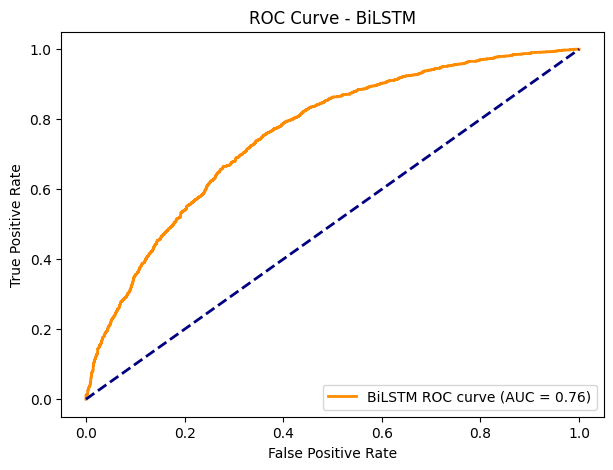

In [18]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test_seq, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'BiLSTM ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - BiLSTM')
plt.legend(loc="lower right")
plt.show()


In [12]:
def predict_spoiler(review_text):
    # 1. Clean the input review
    review_clean = clean_text(review_text)

    # 2. Convert to sequence
    sequence = tokenizer.texts_to_sequences([review_clean])
    padded_seq = pad_sequences(sequence, maxlen=max_len)

    # 3. Predict probability
    prob = model_lstm.predict(padded_seq)[0][0]

    # 4. Apply threshold
    prediction = "SPOILER" if prob > 0.3 else "NOT A SPOILER"

    print(f"\n🔍 Review: {review_text}")
    print(f"📊 Probability of spoiler: {prob:.2f}")
    print(f"📢 Prediction: {prediction}")

    return prediction


In [13]:
predict_spoiler("The main character dies in the final scene.")
predict_spoiler("The cinematography was stunning and the music was great.")
predict_spoiler("The whole movie was just a dream sequence.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step

🔍 Review: The main character dies in the final scene.
📊 Probability of spoiler: 0.25
📢 Prediction: NOT A SPOILER
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step

🔍 Review: The cinematography was stunning and the music was great.
📊 Probability of spoiler: 0.20
📢 Prediction: NOT A SPOILER
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step

🔍 Review: The whole movie was just a dream sequence.
📊 Probability of spoiler: 0.24
📢 Prediction: NOT A SPOILER


'NOT A SPOILER'